# 2-03 공매도 과열종목 지정 — 지정 전후 주가·거래량

**질문 예시:** "이번 달 공매도 과열로 지정된 종목들, 지정 뒤 주가 어떻게 됐어?", "공매도 과열 지정이 많은 날은 시장이 빠진 날이야?"

CHECK 원본(`2_공시뉴스/03_공매도과열`)은 **공매도 거래대금·잔고비중**으로 "왜 지정됐고 지정 후 공매도가 얼마나 줄었나"를 봤습니다.
DeepSearch에는 공매도 수치가 없어서(`research/data_gaps`), **지정 공시**와 **주가·거래량**만으로 다시 짭니다.

| 단계 | DeepSearch 함수 |
|---|---|
| 지정 공시 모으기 | `DocumentSearch(["company"],["disclosure"], 'title:"공매도 과열"')` — 유가증권·코스닥시장본부 공시 |
| 지정 전후 주가·거래량 | `GetStockPrices([종목들], …)` 한 번 |
| 시장 대비 | `GetMarketIndexes` |
| 날짜별 지정 건수 | `DocumentTrends(… interval="1d")` |

**각색한 점**
- 공매도 거래대금·잔고·대차는 없습니다. "지정 직전 공매도 급증"은 볼 수 없고, 대신 **트리거일의 주가 낙폭·거래량 배수**를 봅니다.
- 거래소 시장 공시(공매도 과열·시장경보)는 **2026년 8월부터** 촘촘히 들어 있습니다(그 전은 월 10건 안팎).
  CHECK 예시(6월 리노공업·솔브레인·에스원)는 DeepSearch에 없어 **최근 한 달 지정 종목 전체**로 바꿨습니다.

[![Colab에서 열기](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/beaten-by-the-market/deepsearch/blob/main/scenarios/2_disclosure_news/03_short_overheat.ipynb)

## 0. 준비
Colab 왼쪽 🔑(Secrets)에 `DEEPSEARCH_API_KEY`를 등록하고 이 노트북의 액세스를 켠 뒤 아래 두 셀을 실행하세요. 두 번째 셀은 모든 시나리오에 공통인 헬퍼입니다(접어 두어도 됩니다).

In [1]:
# Colab에서만: 한글 차트 폰트 설치 (로컬에서는 건너뜀)
import sys
if "google.colab" in sys.modules:
    !pip -q install koreanize-matplotlib

In [2]:
# ── DeepSearch 헬퍼 (모든 시나리오 노트북 공통) ─────────────────────────────
# Colab: 왼쪽 🔑(Secrets)에 이름 DEEPSEARCH_API_KEY 로 키를 넣고 "노트북 액세스"를 켜세요.
#        키는 "아이디:비밀번호" 형식이든 base64 문자열이든 됩니다. 키 값은 출력하지 않습니다.
# 로컬: 환경변수 DEEPSEARCH_API_KEY / API_KEY 또는 상위 폴더의 .env 를 읽습니다.
import base64, json, os, sys, time
from datetime import date, datetime, timedelta

import pandas as pd
import requests

IN_COLAB = "google.colab" in sys.modules
API_URL = "https://api.deepsearch.com/v1/compute"

pd.set_option("display.max_columns", 30)
pd.set_option("display.width", 200)
pd.set_option("display.max_colwidth", 60)


def _norm_key(k):
    k = k.strip().strip('"').strip("'")
    return base64.b64encode(k.encode()).decode() if ":" in k else k


def _find_key():
    if IN_COLAB:
        try:
            from google.colab import userdata
            k = userdata.get("DEEPSEARCH_API_KEY")
            if k:
                return _norm_key(k)
        except Exception:
            pass
    for name in ("DEEPSEARCH_API_KEY", "API_KEY"):
        if os.environ.get(name):
            return _norm_key(os.environ[name])
    d = os.path.abspath(os.getcwd())
    while True:
        p = os.path.join(d, ".env")
        if os.path.isfile(p):
            for line in open(p, encoding="utf-8-sig"):
                if "=" in line and not line.strip().startswith("#"):
                    k, v = line.split("=", 1)
                    if k.strip() in ("DEEPSEARCH_API_KEY", "API_KEY") and v.strip():
                        return _norm_key(v)
        if os.path.dirname(d) == d:
            break
        d = os.path.dirname(d)
    from getpass import getpass
    return _norm_key(getpass("DeepSearch API 키: "))


_KEY = _find_key()


class DSError(Exception):
    pass


def ds(query, timeout=180, retries=3):
    """compute 호출 → 응답 JSON. 서버가 돌려준 오류(data.exceptions)는 DSError."""
    last = None
    for i in range(retries):
        try:
            r = requests.post(API_URL, json={"input": query}, timeout=timeout,
                              headers={"Authorization": "Basic " + _KEY})
            body = r.json()
        except Exception as e:  # 네트워크·일시 오류만 재시도
            last = e
            time.sleep(3 * (i + 1))
            continue
        exc = (body.get("data") or {}).get("exceptions") or []
        if exc or r.status_code >= 400:
            msg = "; ".join(f"{x.get('class', '')}: {' '.join(map(str, x.get('args') or [x.get('message', '')]))}"
                            if isinstance(x, dict) else str(x) for x in exc)
            raise DSError(f"{r.status_code} {msg or body}"[:500])
        return body
    raise DSError(f"요청 실패: {last}")


def _pod(body):
    pods = (body.get("data") or {}).get("pods") or []
    return pods[1] if len(pods) >= 2 else {}


def ds_df(query, **kw):
    """DataFrame 결과(재무·시세·경제지표 등) → pandas DataFrame. 결과가 없으면 빈 DataFrame."""
    c = _pod(ds(query, **kw)).get("content") or {}
    data = c.get("data") if isinstance(c, dict) else None
    if not isinstance(data, dict) or not data:
        return pd.DataFrame()
    cols = [x for x in (c.get("columns") or data.keys()) if x in data]
    df = pd.DataFrame({x: data[x] for x in cols})
    for x in ("date", "created_at"):
        if x in df and df[x].dtype == object:
            df[x] = pd.to_datetime(df[x].astype(str).str[:19], errors="coerce")
    return df


def _polarity(x):
    """문서 긍부정: polarity.name, 없으면 customized_ml.kis 모델 값(최근 뉴스는 절반가량이 이쪽에만 있음)."""
    p = x.get("polarity")
    if isinstance(p, dict) and p.get("name"):
        return p["name"]
    k = (((x.get("customized_ml") or {}).get("kis") or {}).get("ip_multitask") or {}).get("polarity") or {}
    return k.get("name")


def doc_search(category, section, query, date_from, date_to, count=100, pages=1):
    """DocumentSearch → (총건수, 문서 DataFrame). category: news/research/company/patent. 기간은 1년 이내.
    종목 지정은 securities.symbol:005930 (접두어 없는 6자리)이 뉴스·리서치·공시 모두에서 가장 정확합니다.
    securities.symbol:KRX:005930 은 키워드 검색으로 바뀌어 건수가 줄고, securities.name: 은 리서치(공식명
    '에스케이하이닉스')·공시(DART명 '현대자동차')에서 놓칩니다(2026-11-25 확인). 여러 종목: securities.symbol:(005930 or 000660)"""
    rows, total = [], 0
    for page in range(1, pages + 1):
        q = (f'DocumentSearch(["{category}"],{json.dumps(section, ensure_ascii=False)},'
             f'{json.dumps(query, ensure_ascii=False)},count={count},page={page},'
             f'date_from={date_from},date_to={date_to})')
        c = _pod(ds(q)).get("content") or {}
        d = c.get("data") if isinstance(c.get("data"), dict) else c
        total = d.get("total_matches") or 0
        docs = d.get("docs") or []
        for x in docs:
            secs = x.get("securities") or []
            rows.append({
                "created_at": pd.to_datetime(str(x.get("created_at"))[:19], errors="coerce"),
                "publisher": x.get("publisher"),
                "title": " ".join(str(x.get("title") or "").split()),
                "stocks": ", ".join(s.get("name", "") for s in secs),
                "symbols": ", ".join(s.get("symbol", "") for s in secs),
                "polarity": _polarity(x),
                "url": x.get("content_url"),
            })
        # 한 페이지가 count 보다 적게 와도(80~90건 흔함) 뒤에 더 있을 수 있다 → 총건수로 판단
        if not docs or page * count >= total:
            break
    cols = ["created_at", "publisher", "title", "stocks", "symbols", "polarity", "url"]
    return total, pd.DataFrame(rows, columns=cols)


def doc_trends(category, section, query, date_from, date_to, interval="1d"):
    """DocumentTrends → DataFrame(date, count)."""
    q = (f'DocumentTrends(["{category}"],{json.dumps(section, ensure_ascii=False)},'
         f'{json.dumps(query, ensure_ascii=False)},interval="{interval}",'
         f'date_from={date_from},date_to={date_to})')
    c = _pod(ds(q)).get("content") or {}
    d = c.get("data") if isinstance(c.get("data"), dict) else c
    trends = d.get("trends") or []
    b = trends[0].get("buckets", []) if trends else []
    df = pd.DataFrame([{"date": x.get("key_as_string") or x.get("key"), "count": x.get("count", 0)} for x in b])
    if not df.empty:
        df["date"] = pd.to_datetime(df["date"].astype(str).str[:19], errors="coerce")
    return df


def stock_prices(entities, date_from, date_to, columns=None):
    """종목 목록의 일별 시세. entities 예: ["KRX:005930", "KRX:000660"] 또는 "KRX:005930".
    가격은 수정주가, 거래량·거래대금·시가총액은 당일 실제 값. change_rate 는 비율(0.01 = 1%)."""
    ents = [entities] if isinstance(entities, str) else list(entities)
    cols = columns or ["open", "high", "low", "close", "volume", "value", "change_rate", "market_cap"]
    q = (f'GetStockPrices([{", ".join(ents)}], columns={json.dumps(cols)}, '
         f'date_from={date_from}, date_to={date_to})')
    return ds_df(q)


_UNIVERSE = None


def universe():
    """현재 상장 종목 기본정보(GetStockSymbols 전 종목): symbol, name, market, industry_name 등.
    company_type_l1: 1 일반법인, 2 공기업(한국전력·기업은행 등 8종목), 8 ETF·ETN 등."""
    global _UNIVERSE
    if _UNIVERSE is None:
        u = ds_df("GetStockSymbols()")
        _UNIVERSE = u.rename(columns={"entity_name": "name"})[
            ["symbol", "name", "market", "company_type_l1", "industry_id", "industry_name", "date_listed",
             "fiscal_year_end", "conglomerate_id"]]
    return _UNIVERSE.copy()


def all_stocks(day, common_only=True, columns=None):
    """day(또는 그 이전 마지막 거래일)의 전 종목 하루치 시세 + 종목 정보. 한 번 호출로 4,000여 종목.
    common_only=True 이면 일반법인·공기업 보통주만(ETF·ETN·우선주 제외)."""
    day = pd.Timestamp(day).date()
    cols = columns or ["open", "high", "low", "close", "volume", "value", "change_rate", "market_cap"]
    snap = ds_df(f'GetStockPrices(columns={json.dumps(cols)}, '
                 f'date_from={day - timedelta(days=7)}, date_to={day})')
    df = snap.merge(universe().drop(columns=["date"], errors="ignore"), on="symbol", how="left")
    if common_only:
        df = df[df["company_type_l1"].isin(["1", "2"]) & df["symbol"].str.endswith("0")]
    df = df[df["market"].isin(["KOSPI", "KOSDAQ", "KONEX"])]
    if "change_rate" in df:
        df["change_pct"] = df["change_rate"] * 100
    return df.reset_index(drop=True)


def index_prices(date_from, date_to):
    """지수 11종(코스피·코스닥 계열) 일별. change_rate 는 퍼센트(1.94 = 1.94%).
    지수의 value(거래대금)는 백만원, volume(거래량)은 천주 단위로 보입니다(코스닥 2026-11-23 value 4,673,819 ≈ 4.7조)."""
    # 지수를 지정하지 않으면 최근 약 1,300행(≈118거래일)만 오고 앞 기간이 조용히 잘린다 → 140일씩 나눠 받는다
    start, end = pd.Timestamp(date_from), pd.Timestamp(date_to)
    parts = []
    while start <= end:
        stop = min(start + pd.Timedelta(days=139), end)
        parts.append(ds_df(f"GetMarketIndexes(date_from={start.date()}, date_to={stop.date()})"))
        start = stop + pd.Timedelta(days=1)
    df = pd.concat([x for x in parts if not x.empty], ignore_index=True) if parts else pd.DataFrame()
    return df.drop_duplicates(["date", "symbol"]).sort_values(["date", "symbol"]).reset_index(drop=True) if not df.empty else df


def fred(series, date_from, date_to):
    """FRED 시리즈 → 날짜 × 시리즈 넓은 표. 예: fred(["DGS10", "DEXKOUS"], "2026-10-01", "2026-11-24")"""
    ids = ", ".join(json.dumps(s) for s in series)
    df = ds_df(f"QueryFredSeriesData([{ids}], date_from={date_from}, date_to={date_to})")
    if df.empty:
        return df
    val = [c for c in df.columns if c not in ("entity_id", "date")][0]
    df["series"] = df["entity_id"].str.replace("FRED:", "", regex=False)
    wide = df.pivot_table(index="date", columns="series", values=val).sort_index()
    return wide[[s for s in series if s in wide.columns]]  # 요청한 순서대로


def krw(v, digits=1):
    """원 → '138.0조' / '5,027억'."""
    if v is None or pd.isna(v):
        return "-"
    a = abs(v)
    if a >= 1e12:
        return f"{v / 1e12:.{digits}f}조"
    if a >= 1e8:
        return f"{v / 1e8:,.0f}억"
    if a >= 1e4:
        return f"{v / 1e4:,.0f}만"
    return f"{v:,.0f}"


PRICE_NOTICE = ("※ 주가는 수정주가입니다(분할·무상증자·유상증자 소급 반영, 배당 미반영). "
                "거래량·거래대금·시가총액은 당일 실제 값이며 KRX 기준입니다(NXT 미포함).")

# 한글 차트 폰트
import matplotlib.pyplot as plt
try:
    import koreanize_matplotlib  # noqa: F401  (Colab: 위 셀에서 설치)
except ImportError:
    if sys.platform.startswith("win"):
        plt.rcParams["font.family"] = "Malgun Gothic"
    elif sys.platform == "darwin":
        plt.rcParams["font.family"] = "AppleGothic"
plt.rcParams["axes.unicode_minus"] = False

print("DeepSearch 준비 완료", "(Colab)" if IN_COLAB else "(로컬)")

DeepSearch 준비 완료 (로컬)


In [3]:
ASOF = "2026-11-24"
FROM = "2026-10-27"        # 지정 공시를 모을 기간 (약 한 달)

## 1. 지정 공시 모으기
제목이 `공매도 과열종목 지정`이면 신규 지정, `연장`이면 지정 연장입니다. 공시는 대개 장 마감 뒤 20시께 나오고, **다음 거래일부터** 공매도가 금지됩니다.

In [4]:
total, d = doc_search("company", ["disclosure"], 'title:"공매도 과열"', FROM, ASOF, count=100, pages=4)
d["구분"] = d["title"].str.contains("연장").map({True: "연장", False: "지정"})
d["시장"] = d["publisher"].map({"유가증권시장본부": "KOSPI", "코스닥시장본부": "KOSDAQ"})
print(f"공매도 과열 공시 {total}건 (받은 것 {len(d)}건)")
print(pd.crosstab(d["시장"], d["구분"], margins=True, margins_name="합계"))
print(f"종목 태그가 없는 공시: {(d['symbols'] == '').sum()}건 — 제목에 우선주 이름만 있거나 태그 누락. 이 노트북에서는 뺍니다.")

공매도 과열 공시 216건 (받은 것 216건)
구분      연장   지정   합계
시장                  
KOSDAQ  37  142  179
KOSPI    4   33   37
합계      41  175  216
종목 태그가 없는 공시: 22건 — 제목에 우선주 이름만 있거나 태그 누락. 이 노트북에서는 뺍니다.


## 2. 트리거일 정하기
20시 공시는 **그날 거래**를 보고 지정한 것이라 공시일을 트리거일 **T**로 둡니다. 장 시작 전(09:30 이전) 공시는 직전 거래일을 T로 봅니다.
같은 종목이 기간 안에 여러 번 지정됐으면 **첫 신규 지정**만 씁니다.

In [5]:
ev = d[(d["구분"] == "지정") & (d["symbols"] != "")].copy()
ev["symbol"] = "KRX:" + ev["symbols"].str.split(", ").str[0]     # 공시 종목코드엔 KRX: 접두어가 없다
ev["종목"] = ev["stocks"].str.split(", ").str[0]
ev = ev.sort_values("created_at").drop_duplicates("symbol")
repeat = d[d["symbols"] != ""].groupby("stocks").size().sort_values(ascending=False)
print(f"신규 지정 종목 {len(ev)}개 | 기간 중 공시가 3건 이상(지정+연장 반복)인 종목:",
      ", ".join(f"{k}({v})" for k, v in repeat[repeat >= 3].items()) or "없음")

p_from = (pd.Timestamp(FROM) - pd.Timedelta(days=45)).date()
px = stock_prices(ev["symbol"].tolist(), p_from, ASOF)

def market_index(d1, d2):
    """GetMarketIndexes 는 긴 기간이면 최근 약 1,300행만 주므로 90일씩 나눠 받는다."""
    parts, cur, end = [], pd.Timestamp(d1), pd.Timestamp(d2)
    while cur <= end:
        nxt = min(cur + pd.Timedelta(days=89), end)
        parts.append(index_prices(cur.date(), nxt.date()))
        cur = nxt + pd.Timedelta(days=1)
    i = pd.concat(parts).drop_duplicates(["date", "symbol"])
    return i[i["symbol"].isin(["KRX:KOSPI", "KRX:KOSDAQ"])].pivot_table(index="date", columns="symbol", values="close")

idx = market_index(p_from, ASOF)
print(PRICE_NOTICE)
print(f"시세 {len(px):,}행")

신규 지정 종목 142개 | 기간 중 공시가 3건 이상(지정+연장 반복)인 종목: CJ ENM(4), 에이전트AI(4), 코아스(3), 마이크로투나노(3), 콜마비앤에이치(3), 큐리언트(3), 에코캡(3), 이지트로닉스(3), 윙스풋(3), 대우건설(3), 코난테크놀로지(3), 바이오인프라(3)


※ 주가는 수정주가입니다(분할·무상증자·유상증자 소급 반영, 배당 미반영). 거래량·거래대금·시가총액은 당일 실제 값이며 KRX 기준입니다(NXT 미포함).
시세 6,816행


## 3. 지정 전후 반응
- **T 수익률·거래량 배수**: 트리거일 하루 등락과, 그날 거래량 ÷ 직전 20거래일 평균. 지정 사유(급락·공매도 급증)의 그림자입니다.
- **T+1, T+3, T+5**: 공매도 금지가 적용된 뒤의 수익률(T 종가 대비). **초과**는 같은 기간 해당 시장 지수 수익률을 뺀 값.

In [6]:
rows = []
for _, e in ev.iterrows():
    s = px[px["symbol"] == e["symbol"]].set_index("date").sort_index()
    if s.empty:
        continue
    t_day = pd.Timestamp(e["created_at"].date())
    if e["created_at"].hour * 100 + e["created_at"].minute < 930:
        t_day -= pd.Timedelta(days=1)
    pos = s.index.searchsorted(t_day, side="right") - 1       # T = t_day 이하 마지막 거래일
    if pos < 20:
        continue
    close, vol = s["close"], s["volume"]
    mi = idx[f"KRX:{e['시장']}"].reindex(s.index)
    r = {"종목": e["종목"], "시장": e["시장"], "T": s.index[pos].date(),
         "T 수익률": (close.iloc[pos] / close.iloc[pos - 1] - 1) * 100,
         "T 지수": (mi.iloc[pos] / mi.iloc[pos - 1] - 1) * 100,
         "T 거래량배수": vol.iloc[pos] / vol.iloc[pos - 20:pos].mean(),
         "T-5~T 수익률": (close.iloc[pos] / close.iloc[pos - 5] - 1) * 100}
    for h in (1, 3, 5):
        if pos + h < len(s):
            rr = close.iloc[pos + h] / close.iloc[pos] - 1
            r[f"T+{h}"] = rr * 100
            r[f"초과 T+{h}"] = (rr - (mi.iloc[pos + h] / mi.iloc[pos] - 1)) * 100
    rows.append(r)
res = pd.DataFrame(rows)
res.round(1).sort_values("T", ascending=False).head(15)

,종목,시장,T,T 수익률,T 지수,T 거래량배수,T-5~T 수익률,T+1,초과 T+1,T+3,초과 T+3,T+5,초과 T+5
141,휴림로봇,KOSDAQ,2026-11-24,29.9,4.8,17.9,71.2,NaN,NaN,NaN,NaN,NaN,NaN
140,한솔홈데코,KOSPI,2026-11-24,-21.3,6.3,13.7,-19.3,NaN,NaN,NaN,NaN,NaN,NaN
139,레인보우로보틱스,KOSDAQ,2026-11-23,-1.5,-1.6,2.1,12.1,17.4,12.6,NaN,NaN,NaN,NaN
138,자이언트스텝,KOSDAQ,2026-11-23,-10.2,-1.6,1.0,11.4,4.4,-0.4,NaN,NaN,NaN,NaN
133,바이오니아,KOSDAQ,2026-11-20,20.1,-5.7,15.3,14.6,-12.6,-11.0,NaN,NaN,NaN,NaN
129,화인베스틸,KOSPI,2026-11-20,-13.1,-5.2,1.0,6.7,-2.2,1.1,NaN,NaN,NaN,NaN
130,스튜디오미르,KOSDAQ,2026-11-20,-15.4,-5.7,4.3,-10.0,-0.3,1.3,NaN,NaN,NaN,NaN
131,지아이이노베이션,KOSDAQ,2026-11-20,-7.0,-5.7,0.7,-6.5,-0.3,1.3,NaN,NaN,NaN,NaN
132,케어젠,KOSDAQ,2026-11-20,-5.8,-5.7,0.7,-5.2,-5.1,-3.5,NaN,NaN,NaN,NaN
134,클리오,KOSDAQ,2026-11-20,-2.9,-5.7,3.7,0.0,-2.3,-0.7,NaN,NaN,NaN,NaN


### 요약 통계
지정 후 5거래일이 지나지 않은 최근 지정은 T+5가 비어 있어 평균에서 빠집니다.

In [7]:
summary = pd.DataFrame({
    "종목 수": res.groupby("시장").size(),
    "T 수익률 중앙값(%)": res.groupby("시장")["T 수익률"].median(),
    "T 하락 비율": res.groupby("시장")["T 수익률"].apply(lambda x: (x < 0).mean()),
    "T 거래량배수 중앙값": res.groupby("시장")["T 거래량배수"].median(),
    "T+1 평균(%)": res.groupby("시장")["T+1"].mean(),
    "T+5 평균(%)": res.groupby("시장")["T+5"].mean(),
    "초과 T+5 평균(%p)": res.groupby("시장")["초과 T+5"].mean(),
    "T+5 상승 비율": res.groupby("시장")["T+5"].apply(lambda x: (x.dropna() > 0).mean()),
})
summary.round(2)

,종목 수,T 수익률 중앙값(%),T 하락 비율,T 거래량배수 중앙값,T+1 평균(%),T+5 평균(%),초과 T+5 평균(%p),T+5 상승 비율
시장,,,,,,,,
KOSDAQ,119,-3.15,0.67,2.39,-2.77,-5.89,-2.18,0.33
KOSPI,23,-6.75,0.83,1.66,-2.27,-4.70,-0.01,0.38


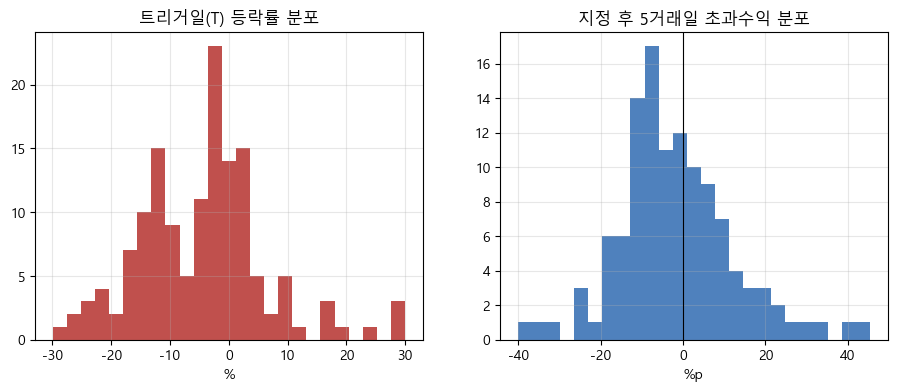

In [8]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
axes[0].hist(res["T 수익률"], bins=25, color="#c0504d")
axes[0].set_title("트리거일(T) 등락률 분포"); axes[0].set_xlabel("%")
axes[1].hist(res["초과 T+5"].dropna(), bins=25, color="#4f81bd")
axes[1].axvline(0, color="k", lw=.8)
axes[1].set_title("지정 후 5거래일 초과수익 분포"); axes[1].set_xlabel("%p")
for a in axes:
    a.grid(alpha=.3)

## 4. 시장 전체: 지정이 몰린 날은 시장이 빠진 날인가
날짜별 신규 지정 공시 건수(`DocumentTrends`)를 코스닥 지수 등락률과 나란히 봅니다. 기간은 수집이 촘촘해진 2026-08 이후입니다.

In [9]:
cnt = doc_trends("company", ["disclosure"], 'title:"공매도 과열종목 지정"', "2026-08-01", ASOF, interval="1d")
k = market_index("2026-07-25", ASOF)["KRX:KOSDAQ"].pct_change() * 100
m = cnt.set_index("date")["count"].to_frame("지정 공시").join(k.rename("코스닥 등락률(%)"), how="inner").dropna()
m = m[m.index.dayofweek < 5]
print(f"거래일 {len(m)}일, 상관계수 {m['지정 공시'].corr(m['코스닥 등락률(%)']):.2f}")
print("지정 공시가 많았던 날 상위 5:")
print(m.sort_values("지정 공시", ascending=False).head(5).round(2).to_string())

거래일 77일, 상관계수 -0.40
지정 공시가 많았던 날 상위 5:
            지정 공시  코스닥 등락률(%)
date                         
2026-11-11     18        5.62
2026-10-29     15       -2.34
2026-08-18     15       -3.52
2026-09-10     14        0.79
2026-11-17     13       -2.34


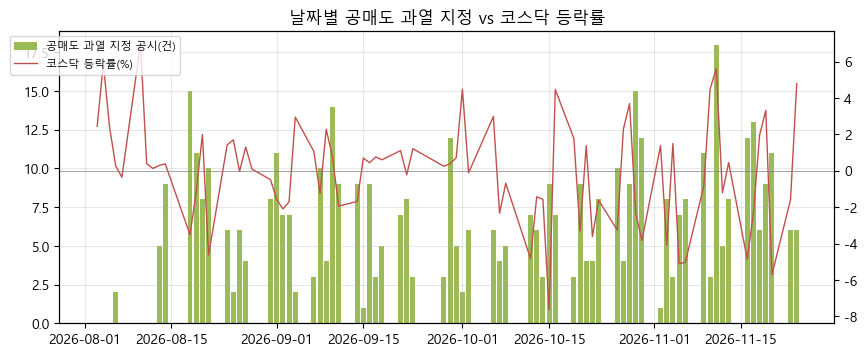

In [10]:
fig, ax = plt.subplots(figsize=(10, 3.8))
ax.bar(m.index, m["지정 공시"], color="#9bbb59", label="공매도 과열 지정 공시(건)")
ax2 = ax.twinx()
ax2.plot(m.index, m["코스닥 등락률(%)"], color="#c0504d", lw=1, label="코스닥 등락률(%)")
ax2.axhline(0, color="gray", lw=.5)
ax.set_title("날짜별 공매도 과열 지정 vs 코스닥 등락률"); ax.grid(alpha=.3)
fig.legend(loc="upper left", bbox_to_anchor=(0.07, 0.88), fontsize=8);

## 결과 읽는 법과 한계
- 공매도 과열 지정 기준에는 **주가 급락**과 **공매도 비중·거래대금 급증**이 들어 있습니다. DeepSearch로는 주가 쪽만 보이므로, T일 급락과 거래량 폭증이 "지정 사유의 그림자"입니다.
- **공매도 거래대금이 지정 뒤 얼마나 줄었는지, 잔고가 언제 풀리는지는 이 데이터로 답할 수 없습니다.** 필요하면 CHECK API나 KRX 정보데이터시스템을 쓰세요.
- 거래소 시장 공시는 2026-08 이전엔 일부만 들어 있어 과거 사례 연구에는 쓰기 어렵습니다.
- 공시의 10% 안팎은 종목 태그가 없어 빠졌습니다(주로 우선주). 본문을 읽어 종목을 채우는 방법은 `2-05 공시 본문`에서 다룹니다.